# MT product optimizer comparison and identifiability

**Question:** How do the product LM and Adam methods compare on identical synthetic MT data, and what does local rank say about identifiability?

**Level 3 — Research critique**  
**Prerequisites:** Levels 1–2 and inverse-problem fundamentals; 35 min.



## Objectives

Question: Which frequency windows resolve the fixed-thickness model locally, and does the Torch optimizer reach the same synthetic solution as the trust-region method?



## Setup

Uses repository modules and committed records through a discovered root; it downloads and mutates nothing. Install exact pins: `pip install numpy==2.2.6 matplotlib==3.10.8` `scipy==1.15.2` is required by the MT forward operator.



## Data

The optimizer experiment uses 60 frequencies from 0.001–100 Hz, fixed layer thicknesses of 300 m and 700 m, a three-layer truth of 80/12/250 Ω·m and one frozen frequency mask. A separate 24-frequency identifiability control tests band-dependent local rank. Clear Lake cl061 remains outside both fits because its measured 1D gate fails.


**Source and rights:** Clear Lake station cl061 EDI, USGS/EarthScope [station product](https://data.earthscope.org/app/products/portal/emtf/emtf_item.html?p=2022%2FMT_TF_USGS-GMEG.2022.cl061), raw object [USGS-GMEG.2022.cl061.edi](https://data.earthscope.org/archive/seismology/products/emtf/surveys/2022/MT_TF_USGS-GMEG.2022.cl061/USGS-GMEG.2022.cl061.edi), and [USGS Clear Lake release](https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california). The source release is marked CC0; the EDI requests citation. This repository uses the attributed QC derivative only and does not redistribute another raw EDI copy. cl061 remains QC-only because its 1D eligibility gate fails.

## Method

The repository’s layered-earth operator uses the half-space response `Z=√(iωμ₀ρ)` and recursively propagates it through finite layers using `k=√(iωμ₀/ρ)`, `w=√(iωμ₀ρ)`, and `t=tanh(kh)`. The basal layer is infinite; geometry is 1D, isotropic and quasi-static. Call the existing `electromagnetics.impedance` and `curves` functions; do not reimplement them. Compare the exact synthetic truth with a stored fitted realization over the committed frequencies, plotting apparent resistivity (Ω·m) and phase (degrees) against period (s). Similar curves do not prove unique resistivity or thickness: dimensionality, static shift, correlated errors and fixed thickness are outside this calibration.

Parameters are log-resistivities: positive by construction, with equal steps representing equal multiplicative changes. Complex residuals use per-real-component sigma; real and imaginary parts both inform the fit. Frequencies are not independent depth samples: sensitivity kernels overlap, so one period does not identify one interface. Local sensitivity and coverage remain conditional on the fixed parameterization and cannot rule out global equivalence.



## Comparison

The research context is not a leaderboard: separate published formulation from the product implementation and its committed evidence. A claim of advance would require independent held-out domains, calibrated uncertainty and replication.



**Comparator scope:** This lesson executes the product `mt-lm` and `mt-adam` solvers on the same synthetic input. It does not execute MTpy or an independent MTpy inversion. The product-scope blocker is an independently implemented/reference 1D MT inversion with documented settings and same-input residual comparison; the existing optimizer agreement is implementation parity only.

In [1]:
from pathlib import Path
from importlib.metadata import version

print("Runtime versions:", {name: version(name) for name in ["numpy", "matplotlib", "scipy"]})
import numpy as np

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir())
# Call the repository layered-earth forward operator on its synthetic calibration target.
import json, sys
from pathlib import Path

sys.path.insert(0, str(root / "data-pipeline"))
import electromagnetics as em
from electromagnetics import impedance, curves

cal = json.loads((root / "data/derived/v2/edi/calibration-two-layer.json").read_text(encoding="utf-8"))
f = cal["frequencies_hz"]
rho = cal["calibration_model"]
h = cal["fixed_thickness_m"]
z = impedance(rho, h, f)
truth = curves(z, f)
print("synthetic rho Ω·m", rho, "fixed thickness m", h, "n frequencies", len(f))


Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8', 'scipy': '1.15.2'}
synthetic rho Ω·m [180.0, 20.0] fixed thickness m [450.0] n frequencies 24


### Conductance trade-off at fixed thickness

Thickness and resistivity change together; the whitened impedance residual measures how this frequency set distinguishes that perturbation.

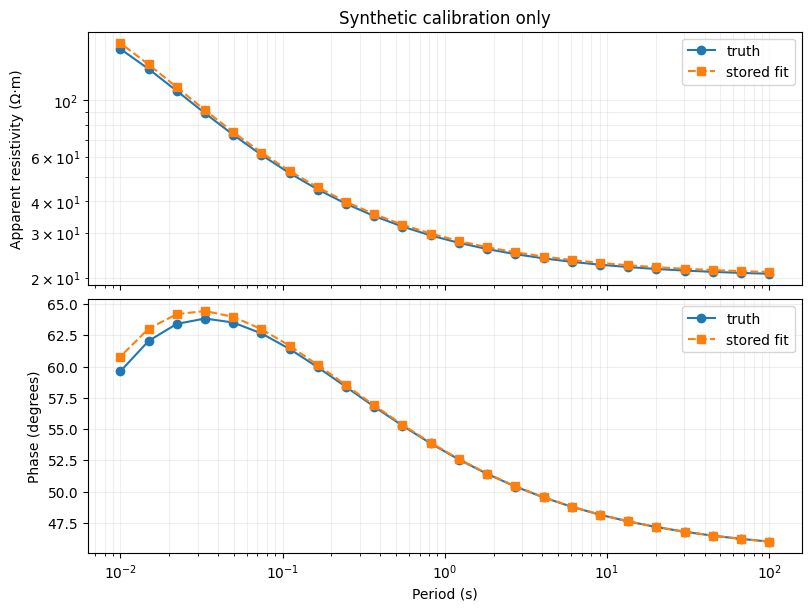

stored fitted rho Ω·m [198.92475596650235, 20.323660137129647]


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Forward-project a stored fitted model and compare physical response curves.
import matplotlib.pyplot as plt

fit = cal["rows"][0]["model"]
other = curves(impedance(fit, h, f), f)
T = 1 / np.asarray(f)
fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True, constrained_layout=True)
ax[0].loglog(T, truth["apparent"], "o-", label="truth")
ax[0].loglog(T, other["apparent"], "s--", label="stored fit")
ax[1].semilogx(T, truth["phase"], "o-", label="truth")
ax[1].semilogx(T, other["phase"], "s--", label="stored fit")
ax[0].set_ylabel("Apparent resistivity (Ω·m)")
ax[1].set_ylabel("Phase (degrees)")
ax[1].set_xlabel("Period (s)")
[a.grid(True, which="both", alpha=0.2) or a.legend() for a in ax]
ax[0].set_title("Synthetic calibration only")
plt.show()
print("stored fitted rho Ω·m", fit)


### Synthetic experiment: frequency coverage, noise and thickness trade-off

This additional **synthetic forward experiment** is separate from measured `cl061`. The repository layered-earth operator creates an exact three-layer response. Its implemented `identifiability` routine linearizes in log-resistivity while holding both thicknesses fixed. Compare the full frequency band with low-only and high-only subsets using identical model and per-component uncertainty. Singular values and local log-resistivity SD are conditional sensitivity diagnostics, not posterior uncertainty or proof of uniqueness.

A second forward-only perturbation increases the thickness and resistivity of the finite conductive layer together, approximately preserving conductance (`h/ρ`). Compare the complex response change with the declared noise scale. This familiar equivalence is approximate for a finite-frequency layered response. It demonstrates the fixed-thickness assumption; it is not a second inversion, a claim of recovered geology, or evidence about `cl061`.

In [3]:
# Synthetic experiment only: fixed-thickness local sensitivity across frequency windows.
f_syn = np.logspace(-3, 2, 60)
active_syn = np.arange(len(f_syn)) % 4 != 1
h_syn = np.array([300.0, 700.0])
rho_syn = np.array([80.0, 12.0, 250.0])
z_syn = impedance(rho_syn, h_syn, f_syn)
sigma_syn = np.maximum(0.03 * np.abs(z_syn), 1e-12)  # SD of each independent real and imaginary component
bands = {
    "full 0.001–100 Hz": np.ones(len(f_syn), dtype=bool),
    "low frequency ≤0.1 Hz": f_syn <= 0.1,
    "high frequency ≥1 Hz": f_syn >= 1.0,
}


### Evaluate frequency-window sensitivity

Identifiability uses one fixed-thickness model and its component uncertainties. The sweep contrasts local rank and parameter sensitivity across full, low and high frequency subsets.

In [4]:
# Evaluate frequency-window sensitivity.
diags = {}
for label, mask in bands.items():
    d = em.identifiability(rho_syn, h_syn, f_syn, sigma_syn, mask)
    diags[label] = d
    print(
        label,
        "N=",
        int(mask.sum()),
        "effective rank=",
        d["effective_rank"],
        "/",
        d["parameter_count"],
        "singular values=",
        np.round(d["singular_values"], 3),
        "local log-rho SD=",
        np.round(d["local_logrho_sd"], 3),
        "unresolved layers=",
        d["unresolved_layers"],
        "status=",
        d["status"],
    )


full 0.001–100 Hz N= 60 effective rank= 3 / 3 singular values= [107.981  61.827  27.976] local log-rho SD= [0.036 0.011 0.015] unresolved layers= [] status= locally_resolved
low frequency ≤0.1 Hz N= 24 effective rank= 2 / 3 singular values= [71.098 31.793  0.1  ] local log-rho SD= [9.974 0.668 0.022] unresolved layers= [0] status= unresolved
high frequency ≥1 Hz N= 24 effective rank= 3 / 3 singular values= [64.944 27.966  6.79 ] local log-rho SD= [0.036 0.017 0.147] unresolved layers= [] status= locally_resolved


### Test the finite-layer conductance trade-off

The sensitivity sweep reports Jacobian rank and local uncertainty for each frequency window. This separate forward calculation perturbs finite-layer thickness and resistivity together, then measures the resulting noise-whitened impedance discrepancy.

In [5]:
# Forward-only h/rho-preserving perturbation of the finite conductive layer.
rho_trade = np.array([rho_syn[0], rho_syn[1] * 1.15, rho_syn[2]])
h_trade = np.array([h_syn[0], h_syn[1] * 1.15])
z_trade = impedance(rho_trade, h_trade, f_syn)
whitened = np.abs(z_trade - z_syn) / sigma_syn
trade_wrms = float(np.sqrt(np.mean(whitened**2) / 2))
print("Synthetic conductance trade-off; baseline h m=", h_syn, "rho ohm m=", rho_syn)
print("Perturbed h m=", h_trade, "rho ohm m=", rho_trade, "; whitened component WRMS=", trade_wrms)


Synthetic conductance trade-off; baseline h m= [300. 700.] rho ohm m= [ 80.  12. 250.]
Perturbed h m= [300. 805.] rho ohm m= [ 80.   13.8 250. ] ; whitened component WRMS= 0.5429574698818997


Run the bounded trust-region method on the fresh synthetic response.

In [6]:
# Run the bounded trust-region method on the fresh synthetic response.
active_syn = np.arange(len(f_syn)) % 4 != 1
fit_lm = em.invert_mt(
    h_syn, f_syn, z_syn, sigma_syn, active=active_syn, initial=rho_syn * 1.2, methods=("mt-lm",), max_nfev=120
)["mt-lm"]
print("LM model Ω·m:", np.round(fit_lm["model"], 3), "WRMS:", fit_lm["metrics"]["active_component_wrms"])


LM model Ω·m: [ 79.987  12.001 249.984] WRMS: 0.0006162534002809828


Run the alternative CPU method with identical data and initial model.

In [7]:
import os
# Run the Torch-backed product optimizer in the repository's isolated pipeline environment.
import json, os, subprocess
from pathlib import Path

work = Path(os.environ["CAOS_TEMP_ROOT"]) / "caos-geophysics-mt-notebook"
work.mkdir(parents=True, exist_ok=True)
input_path = work / "mt-adam-input.json"
output_path = work / "mt-adam-output.json"
request = {
    "h": h_syn.tolist(),
    "f": f_syn.tolist(),
    "rho": rho_syn.tolist(),
    "sigma": sigma_syn.tolist(),
    "active": active_syn.tolist(),
    "z_real": z_syn.real.tolist(),
    "z_imag": z_syn.imag.tolist(),
    "initial": (rho_syn * 1.2).tolist(),
}
input_path.write_text(json.dumps(request), encoding="utf-8")
engine_root = Path(os.environ.get("CAOS_SOURCE_ROOT", root))
engine = engine_root / ".venv-pipeline" / "Scripts" / "python.exe"
if not engine.is_file():
    raise RuntimeError("The isolated pipeline environment is required for Torch-backed mt-adam.")


### Assemble the isolated optimizer request

The request is written beneath the configured temporary root and the dedicated pipeline interpreter is checked before the child process is assembled. No notebook approximation of the Torch method is introduced.

In [8]:
# Assemble the isolated optimizer request.
child = "\n".join(
    [
        "import json, sys",
        "from pathlib import Path",
        "import numpy as np",
        "sys.path.insert(0, str(Path(sys.argv[1]) / 'data-pipeline'))",
        "import electromagnetics as em",
        "source = json.loads(Path(sys.argv[2]).read_text(encoding='utf-8'))",
        "z = np.asarray(source['z_real']) + 1j * np.asarray(source['z_imag'])",
        "fit = em.invert_mt(",
    "    source['h'], source['f'], z, source['sigma'],",
    "    active=source['active'], initial=source['initial'],",
    "    methods=('mt-adam',), adam_steps=1200,",
    ")['mt-adam']",
        "answer = {",
    "    'model': np.asarray(fit['model']).tolist(),",
    "    'active_wrms': float(fit['metrics']['active_component_wrms']),",
    "    'heldout_wrms': float(fit['metrics']['withheld_component_wrms']),",
    "}",
        "Path(sys.argv[3]).write_text(json.dumps(answer), encoding='utf-8')",
    ]
)


### Run the product Adam method

This child program imports the repository implementation in the isolated pipeline environment, calls `invert_mt` with `mt-adam`, and serializes the recovered model plus active and held-out metrics for this kernel.

In [9]:
# Run the product Adam method.
completed = subprocess.run(
    [str(engine), "-c", child, str(root), str(input_path), str(output_path)],
    cwd=root,
    capture_output=True,
    text=True,
    timeout=300,
)
if completed.returncode:
    raise RuntimeError(completed.stderr[-3000:])
adam_result = json.loads(output_path.read_text(encoding="utf-8"))
print(
    "Adam model Ω·m:",
    np.round(adam_result["model"], 3),
    "active WRMS:",
    adam_result["active_wrms"],
    "held-out WRMS:",
    adam_result["heldout_wrms"],
)


Adam model Ω·m: [ 79.987  12.001 249.984] active WRMS: 0.0006162534252895064 held-out WRMS: 0.0005956383478404238


### Plot the sensitivity and trade-off results

This cell visualizes the sensitivity ranks and parameter trade-off computed above; it does not fit or score field data.


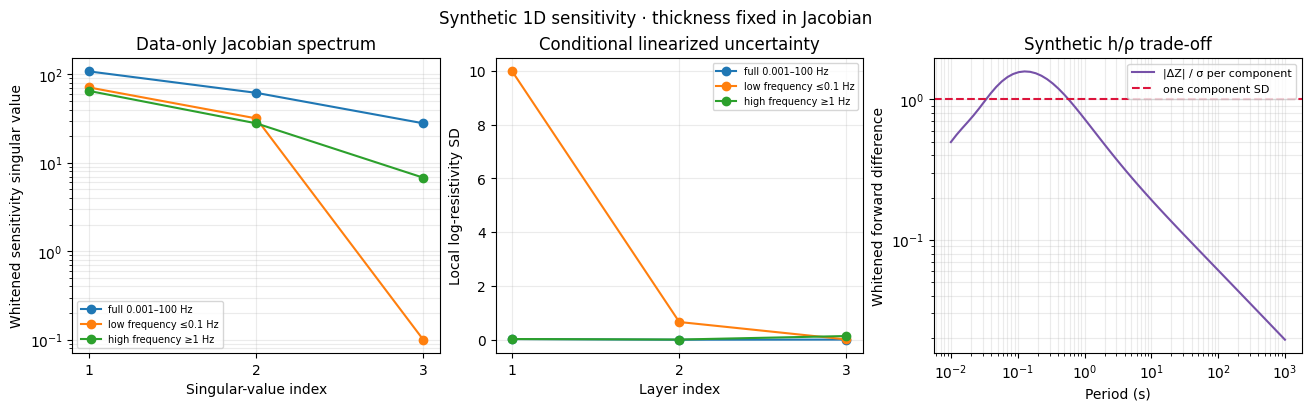

In [10]:
# Execute the documented experiment with the repository evidence.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for label, d in diags.items():
    s = np.asarray(d["singular_values"], float)
    ax[0].semilogy(np.arange(1, len(s) + 1), s, marker="o", label=label)
    ax[1].plot(np.arange(1, len(rho_syn) + 1), d["local_logrho_sd"], marker="o", label=label)
ax[0].set_xlabel("Singular-value index")
ax[0].set_ylabel("Whitened sensitivity singular value")
ax[0].set_title("Data-only Jacobian spectrum")
ax[1].set_xlabel("Layer index")
ax[1].set_ylabel("Local log-resistivity SD")
ax[1].set_title("Conditional linearized uncertainty")
for a in ax[:2]:
    a.set_xticks(np.arange(1, 4))
    a.grid(True, which="both", alpha=0.25)
    a.legend(fontsize=7)
T = 1 / f_syn
ax[2].loglog(T, whitened, label="|ΔZ| / σ per component", color="#7651a8")
ax[2].axhline(1, color="crimson", ls="--", label="one component SD")
ax[2].set_xlabel("Period (s)")
ax[2].set_ylabel("Whitened forward difference")
ax[2].set_title("Synthetic h/ρ trade-off")
ax[2].grid(True, which="both", alpha=0.25)
ax[2].legend(fontsize=8)
fig.suptitle("Synthetic 1D sensitivity · thickness fixed in Jacobian")
plt.show()


The comparison holds data, initialization, active mask and fixed thickness constant while changing the numerical route. LM uses bounded trust-region least squares; Adam optimizes the same uncertainty-scaled complex residual and adjacent log-resistivity penalty. Their near-identical result is an implementation-parity check, not a second geological observation. Local Jacobian rank is evaluated separately for full, low and high bands; rank loss at low frequency warns that this subset cannot constrain every layer. Global alternatives, static shift and 2D/3D structure are outside the experiment.


## Results

The low-frequency Jacobian has rank 2/3 and top-layer local log-resistivity SD 9.974, while the full and high-frequency windows have rank 3/3. LM and Adam both recover approximately [79.987, 12.001, 249.984] Ω·m; active WRMS is 0.000616 for each.
### Frozen optimizer inputs

LM and Adam share one synthetic impedance vector and holdout; the identifiability sweep changes only the frequency subset.

**Answer:** The low-frequency Jacobian has rank 2/3 and top-layer local log-resistivity SD 9.974, while the full and high-frequency windows have rank 3/3. LM and Adam both recover approximately [79.987, 12.001, 249.984] Ω·m; active WRMS is 0.000616 for each.


## Summary

The low-frequency subset leaves one layer locally unresolved despite the full-band result. LM/Adam agreement verifies two implementations on this synthetic objective; it does not establish global uniqueness, realistic noise, dimensionality, or field transfer.



**Scope limit:** No independent MTpy inversion is run here; this is a comparison between two product solvers, not a comparison against independent software.

## References

- [https://github.com/MTgeophysics/mtpy-v2](https://github.com/MTgeophysics/mtpy-v2)
- [https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california](https://www.usgs.gov/data/magnetotelluric-data-clear-lake-region-northern-california)

EarthScope cl061 product record: https://data.earthscope.org/app/products/portal/emtf/emtf_item.html?p=2022%2FMT_TF_USGS-GMEG.2022.cl061. The USGS dataset DOI, citation and CC0 derivative-only decision are stated in Data above.